# Sentinal AI: Exploring the Bot-Detection Dataset

This notebook is a practical look at the account data used by the project. We will check the labels and basic data quality, compare a few profile signals, and then review the saved model benchmark. The aim is to understand what is in the dataset before interpreting model scores.

The benchmark has 37,438 labeled profiles: 25,013 human accounts and 12,425 bot accounts. These are historical dataset labels; they are useful for analysis, but they are not proof about any current account.

**Unit of analysis:** one row represents one account, not one tweet. If tweet data is used later, it should be aggregated per account before model evaluation so that the same person is not represented in both train and test data.

## 1. Set up the notebook

The project dependencies are listed in `requirements.txt`. In VS Code, select the **Python 3 (Sentinal AI)** kernel for this notebook. The next cell sets plot styling and finds the project files whether the notebook is launched from the repository root or its `notebooks` folder.

In [5]:
import os
import sys
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Set plotting aesthetics
%matplotlib inline
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['figure.figsize'] = (10, 6)

# Project Root
ROOT_DIR = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
PROCESSED_FILE = ROOT_DIR / 'data' / 'processed' / 'features_matrix.csv'
INTERIM_FILE = ROOT_DIR / 'data' / 'interim' / 'clean_accounts.csv'

print(f"Project root: {ROOT_DIR}")
print(f"Processed features file exists: {PROCESSED_FILE.exists()}")

Project root: c:\Users\VARDHAN\Downloads\SENITAL AI
Processed features file exists: True


## 2. Load the cleaned account table

This analysis starts from `data/interim/clean_accounts.csv`, created by `src/data/loader.py`. That cleaning step standardizes text and count fields and adds the binary `is_bot` target while keeping the readable `account_type` label for analysis. If the file is missing, run the data download and cleaning steps from the README first.

Total Accounts: 37,438

Class Distribution:


account_type
human    25013
bot      12425
Name: count, dtype: int64

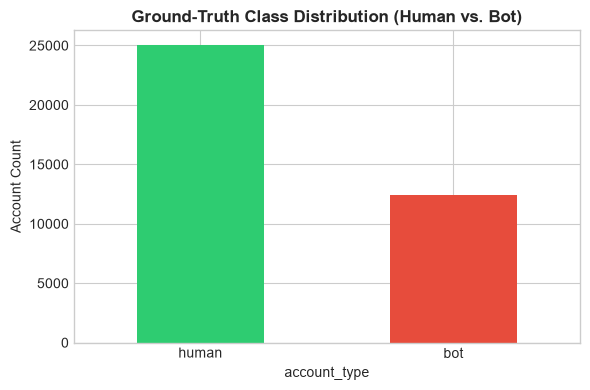

In [6]:
df_clean = pd.read_csv(INTERIM_FILE)
print(f"Total Accounts: {len(df_clean):,}")
print("\nClass Distribution:")
display(df_clean['account_type'].value_counts())

# Visualizing class balance
fig, ax = plt.subplots(figsize=(6, 4))
df_clean['account_type'].value_counts().plot(kind='bar', color=['#2ecc71', '#e74c3c'], ax=ax, rot=0)
ax.set_title('Ground-Truth Class Distribution (Human vs. Bot)', fontweight='bold')
ax.set_ylabel('Account Count')
plt.tight_layout()
plt.show()

### A first read of the class counts

The chart shows how many examples are available for each label. Humans make up about two thirds of this dataset, so a model can look accurate while still missing a meaningful share of bots. That is why the benchmark also reports precision, recall, F1, ROC-AUC, and PR-AUC rather than accuracy alone.

## 3. Compare account behavior

The table below compares group medians for several counters. Medians give a useful starting point because a small number of very large accounts can pull averages upward. The boxplots use `log(1 + value)` to make the wide ranges easier to see; they hide individual outlier points for readability, not from the underlying analysis.

account_type,bot,human
followers_count,25.0,1046.0
friends_count,31.0,474.0
statuses_count,2178.0,7551.0
favourites_count,1131.0,3649.0
account_age_days,2882.0,3395.0


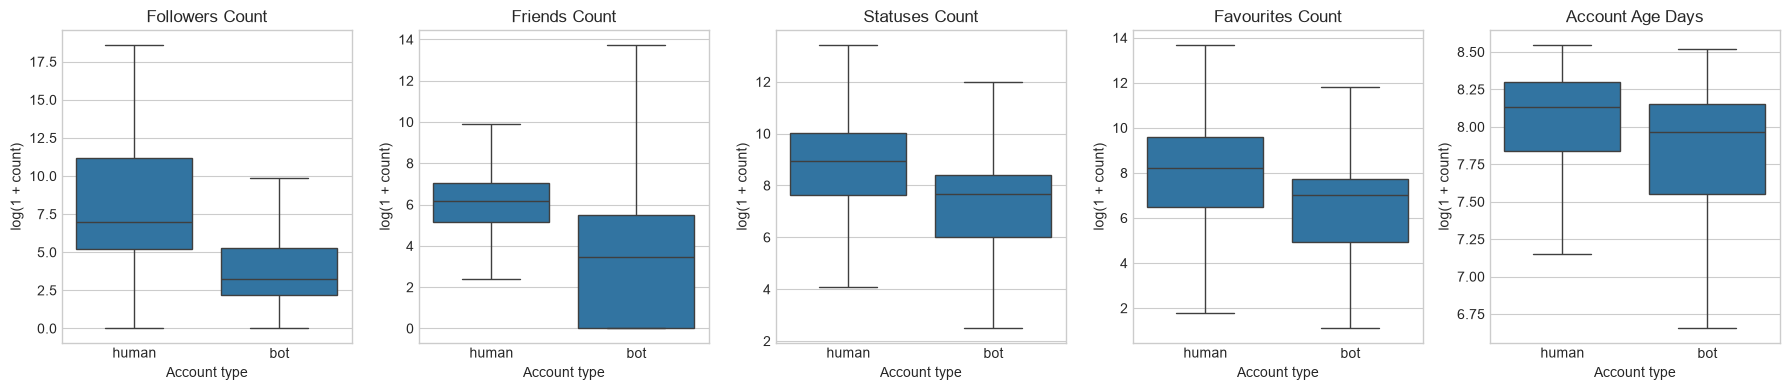

In [7]:
metrics = ['followers_count', 'friends_count', 'statuses_count', 'favourites_count', 'account_age_days']
median_table = df_clean.groupby('account_type')[metrics].median().T
display(median_table)

# Count features have long right tails, so plot log1p values for a readable comparison.
fig, axes = plt.subplots(1, len(metrics), figsize=(18, 4))
for ax, metric in zip(axes, metrics):
    plot_data = df_clean[['account_type', metric]].copy()
    plot_data['log_value'] = np.log1p(pd.to_numeric(plot_data[metric], errors='coerce').clip(lower=0))
    sns.boxplot(data=plot_data, x='account_type', y='log_value', order=['human', 'bot'], showfliers=False, ax=ax)
    ax.set_title(metric.replace('_', ' ').title())
    ax.set_xlabel('Account type')
    ax.set_ylabel('log(1 + count)')
plt.tight_layout()
plt.show()

### Notes on interpreting these comparisons

In this dataset, the human group has higher median follower, following, post, and like counts than the bot group. Account age differs less, and the distributions still overlap. These are group-level patterns, not rules for classifying an individual profile; no single counter establishes that an account is automated.

## 4. Check data quality and engineered features

Before looking at model results, it helps to confirm the table is usable. This cell summarizes missing values and data types, checks duplicate account IDs when that column is present, and inspects the saved numeric feature matrix for missing or infinite values.

In [8]:
quality = pd.DataFrame({
    'dtype': df_clean.dtypes.astype(str),
    'missing_values': df_clean.isna().sum(),
    'missing_percent': (df_clean.isna().mean() * 100).round(2)
})
display(quality.sort_values('missing_values', ascending=False).head(12))
print(f"Duplicate account IDs: {df_clean['id'].duplicated().sum() if 'id' in df_clean.columns else 'id column not available'}")

if PROCESSED_FILE.exists():
    feature_df = pd.read_csv(PROCESSED_FILE)
    feature_columns = feature_df.drop(columns=['is_bot'], errors='ignore').select_dtypes(include=np.number)
    print(f"Feature matrix shape: {feature_df.shape}")
    print(f"Missing feature values: {feature_columns.isna().sum().sum()}")
    print(f"Infinite feature values: {np.isinf(feature_columns.to_numpy()).sum()}")
    display(feature_df.head(3))
else:
    print("Feature matrix not found. Run python src/features/engineering.py to create it.")

,dtype,missing_values,missing_percent
lang,str,7957,21.25
description,str,7257,19.38
profile_background_image_url,str,4499,12.02
location,str,18,0.05
profile_image_url,str,1,0.00
default_profile_image,bool,0,0.00
created_at,str,0,0.00
default_profile,bool,0,0.00
geo_enabled,bool,0,0.00
friends_count,int64,0,0.00


Duplicate account IDs: 0
Feature matrix shape: (37438, 24)
Missing feature values: 0
Infinite feature values: 0


,log_followers,log_friends,log_statuses,log_favourites,log_account_age,reputation_ratio,follow_ratio,activity_intensity,like_to_tweet_ratio,average_tweets_per_day,...,description_word_count,has_description,has_url_in_desc,has_location,default_profile,default_profile_image,geo_enabled,verified,profile_completeness,is_bot
0,7.371489,1.609438,9.309461,1.609438,7.247081,0.996863,2.824934,7.863960,0.000362,7.870,...,18,1,0,0,0,0,0,0,3,1
1,6.758095,6.781058,5.533389,6.285998,7.229839,0.493969,0.868532,0.182609,2.118577,0.183,...,24,1,0,1,0,0,0,0,4,0
2,5.153292,6.388561,6.909753,8.104099,7.056175,0.224250,0.697469,0.862931,3.300399,0.864,...,10,1,0,1,0,0,1,0,5,0


### What to take from the checks

A clean feature matrix should have finite numeric inputs and a target column named `is_bot`. Missing profile fields are normal in real data; the cleaning and feature pipeline supplies safe defaults for model inputs. If the matrix is absent, create it with `python src/features/engineering.py` after cleaning the account table.

## 5. Review the saved benchmark

The leaderboard is produced by `src/models/train_benchmark.py`. Its evaluation uses a stratified train/test split and five-fold cross-validation on the training partition. The results below are tied to this dataset, split, and model artifact; they should not be read as a guarantee of performance on current platform data.

In [9]:
leaderboard_file = ROOT_DIR / 'docs' / 'benchmarks' / 'leaderboard.csv'
if leaderboard_file.exists():
    leaderboard = pd.read_csv(leaderboard_file)
    display(leaderboard)
else:
    print("Run 'python src/models/train_benchmark.py' to generate leaderboard.")

,Model,CV F1 (Mean),CV ROC-AUC,Test Accuracy,Test Precision,Test Recall,Test F1-Score,Test ROC-AUC,Test PR-AUC,Train Time (s),Inference Latency (ms/sample)
0,Logistic Regression (Baseline),0.719717,0.860958,0.786458,0.641805,0.806841,0.714922,0.863007,0.744483,0.05,0.0011
1,Random Forest,0.818272,0.939174,0.885016,0.856140,0.785513,0.819307,0.940888,0.911500,3.00,0.0228
2,XGBoost Classifier,0.817438,0.941487,0.876068,0.798619,0.837827,0.817753,0.941763,0.912480,0.70,0.0051


### Wrap-up

The notebook shows three useful things: the dataset is moderately imbalanced, account behavior differs across labels but the groups overlap, and feature quality should be checked before interpreting benchmark results. A practical next step is to review the confusion matrix and precision-recall curve in `docs/figures/`, then validate the model on recent, representative examples before using it outside a demonstration or research setting.